# B3 — Predicting Star Ratings of E-Commerce Clothing Reviews
AI-101 ML Assignment | Pool B | 5-class ordinal classification

Data: Kaggle `nicapotato/womens-ecommerce-clothing-reviews`. Download:
`kaggle datasets download -d nicapotato/womens-ecommerce-clothing-reviews --unzip -p data/`
(or upload the CSV manually into `data/`).

In [1]:
# !pip install -q scikit-learn pandas matplotlib seaborn jinja2
import os, glob, json, time, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

SEED = 42
np.random.seed(SEED)
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
print('Python', platform.python_version(), '| sklearn', sklearn.__version__, '| seed', SEED)

Python 3.14.3 | sklearn 1.9.1 | seed 42


## 3. Dataset Used — load and clean

In [2]:
path = glob.glob('data/*.csv')[0]
raw = pd.read_csv(path)
n_raw = len(raw)
raw = raw.drop(columns=[c for c in raw.columns if c.startswith('Unnamed')])
print('raw rows:', n_raw, '| columns:', list(raw.columns))
print('missing per column:\n', raw.isna().sum())

df = raw.dropna(subset=['Review Text']).copy()
df = df[df['Review Text'].str.strip() != ''].copy()                  # cleaning: empty review text
n_empty = n_raw - len(df)
df['Title'] = df['Title'].fillna('')
df['text'] = (df['Title'] + '. ' + df['Review Text']).str.strip()    # merge title and text
df['review_len'] = df['text'].str.split().str.len()
df['log_pos_fb'] = np.log1p(df['Positive Feedback Count'])
for c in ['Division Name', 'Department Name', 'Class Name']:
    df[c] = df[c].fillna('Missing')
df = df.reset_index(drop=True)
print(f'rows removed (empty review text): {n_empty} | rows after cleaning: {len(df)}')

# LEAKAGE RULE: 'Recommended IND' is filled in by the customer together with the rating. It is NEVER used as an input.
NUM = ['Age', 'log_pos_fb', 'review_len']
CAT = ['Division Name', 'Department Name', 'Class Name']
TEXT = 'text'
y = df['Rating'].values
X = df[[TEXT] + NUM + CAT]
assert 'Recommended IND' not in X.columns

raw rows: 23486 | columns: ['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']
missing per column:
 Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64


rows removed (empty review text): 845 | rows after cleaning: 22641


## 4. Dataset Statistics and EDA

Rating distribution (%):
 Rating
1     3.6
2     6.8
3    12.5
4    21.7
5    55.4
Name: proportion, dtype: float64

Age: mean 43.3 sd 12.3 | review length: mean 63.2 median 62 words

Mean review length by rating:
 Rating
1    61.6
2    65.5
3    67.7
4    66.6
5    60.7
Name: review_len, dtype: float64

Mean rating by department:
                  count  mean
Department Name             
Bottoms           3662  4.28
Dresses           6145  4.14
Intimate          1653  4.27
Jackets           1002  4.25
Missing             13  5.00
Tops             10048  4.16
Trend              118  3.84



vocabulary size (all data, EDA only): 14679


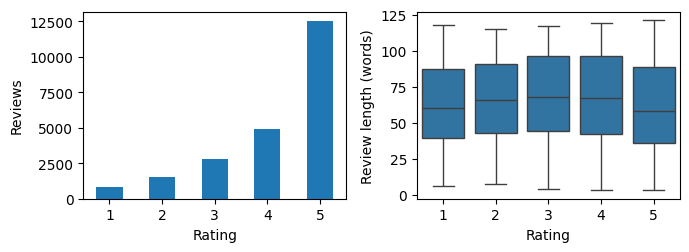

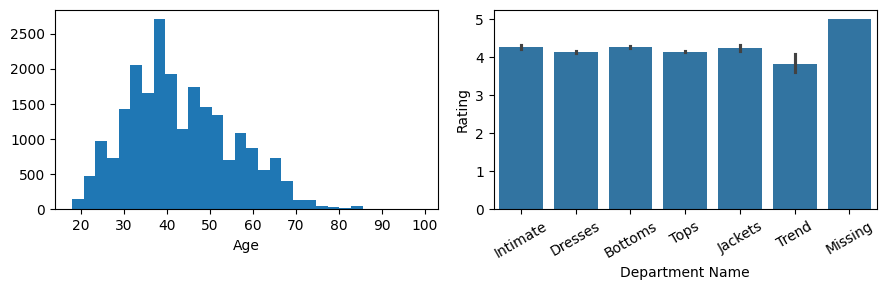

In [3]:
print('Rating distribution (%):\n', (df['Rating'].value_counts(normalize=True).sort_index() * 100).round(1))
print('\nAge: mean %.1f sd %.1f | review length: mean %.1f median %.0f words' % (df.Age.mean(), df.Age.std(), df.review_len.mean(), df.review_len.median()))
print('\nMean review length by rating:\n', df.groupby('Rating')['review_len'].mean().round(1))
print('\nMean rating by department:\n', df.groupby('Department Name')['Rating'].agg(['count', 'mean']).round(2))
vocab_size = TfidfVectorizer().fit(df['text']).vocabulary_.__len__()
print('\nvocabulary size (all data, EDA only):', vocab_size)

# KEY EDA FIGURE
fig, ax = plt.subplots(1, 2, figsize=(7, 2.6))
df['Rating'].value_counts().sort_index().plot.bar(ax=ax[0]); ax[0].set_xlabel('Rating'); ax[0].set_ylabel('Reviews'); ax[0].tick_params(axis='x', rotation=0)
sns.boxplot(data=df, x='Rating', y='review_len', ax=ax[1], showfliers=False); ax[1].set_xlabel('Rating'); ax[1].set_ylabel('Review length (words)')
plt.tight_layout(); plt.savefig('figures/b3_eda.png', dpi=300); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(df.Age, bins=30); ax[0].set_xlabel('Age'); sns.barplot(data=df, x='Department Name', y='Rating', ax=ax[1]); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig('figures/b3_eda_extra.png', dpi=200); plt.show()

## 5.2 Data split: stratified 70/15/15, fixed seed. All vectorisers, scalers and encoders are inside pipelines fitted on training data only.

In [4]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print('train/val/test:', len(X_tr), len(X_va), len(X_te))
for n, a in [('train', y_tr), ('val', y_va), ('test', y_te)]:
    print(n, np.bincount(a, minlength=6)[1:])

def make_pre(use_text=True, use_struct=True):
    t = []
    if use_text:
        t.append(('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=20000, sublinear_tf=True), TEXT))
    if use_struct:
        t.append(('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM))
        t.append(('cat', OneHotEncoder(handle_unknown='ignore'), CAT))
    return ColumnTransformer(t)

def make_clf(kind, C, cw):
    if kind == 'logreg': return LogisticRegression(C=C, class_weight=cw, max_iter=3000)
    if kind == 'linsvm': return LinearSVC(C=C, class_weight=cw, max_iter=10000)
    if kind == 'rf': return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight=cw, n_jobs=-1, random_state=SEED)

def metrics(y_true, y_pred):
    labels = sorted(np.unique(y_true))
    d = dict(accuracy=accuracy_score(y_true, y_pred), macro_f1=f1_score(y_true, y_pred, average='macro'),
             weighted_f1=f1_score(y_true, y_pred, average='weighted'), ordinal_mae=float(np.mean(np.abs(y_true - y_pred))))
    for l, r in zip(labels, recall_score(y_true, y_pred, average=None, labels=labels)):
        d[f'recall_{l}'] = r
    return d

train/val/test: 15848 3396 3397
train [ 575 1084 1976 3435 8778]
val [ 123  233  423  736 1881]
test [ 123  232  424  737 1881]


### 5.1 / 5.3 Models: Logistic Regression, Linear SVM, Random Forest, each with and without class weighting. C chosen on the validation set.

In [5]:
SEARCH = {'logreg': [0.1, 1, 10], 'linsvm': [0.05, 0.5, 5], 'rf': [None]}
val_rows, pipes = [], {}
for kind, Cs in SEARCH.items():
    for cw in [None, 'balanced']:
        for Cval in Cs:
            t0 = time.time()
            p = Pipeline([('pre', make_pre()), ('clf', make_clf(kind, Cval, cw))]).fit(X_tr, y_tr)
            m = metrics(y_va, p.predict(X_va))
            val_rows.append(dict(model=kind, class_weight=str(cw), C=Cval, val_macro_f1=m['macro_f1'], val_acc=m['accuracy']))
            pipes[(kind, str(cw), Cval)] = p
            print(f'{kind:7s} cw={str(cw):9s} C={Cval}  val macro-F1 {m["macro_f1"]:.3f}  acc {m["accuracy"]:.3f}  ({time.time()-t0:.0f}s)')
val_df = pd.DataFrame(val_rows); val_df.to_csv('results/b3_validation.csv', index=False)
display(val_df)

logreg  cw=None      C=0.1  val macro-F1 0.228  acc 0.589  (5s)


logreg  cw=None      C=1  val macro-F1 0.415  acc 0.662  (9s)


logreg  cw=None      C=10  val macro-F1 0.457  acc 0.653  (17s)


logreg  cw=balanced  C=0.1  val macro-F1 0.446  acc 0.593  (6s)


logreg  cw=balanced  C=1  val macro-F1 0.492  acc 0.636  (9s)


logreg  cw=balanced  C=10  val macro-F1 0.466  acc 0.634  (15s)


... (5 outputs left out)

linsvm  cw=balanced  C=5  val macro-F1 0.434  acc 0.621  (18s)


rf      cw=None      C=None  val macro-F1 0.220  acc 0.584  (36s)


rf      cw=balanced  C=None  val macro-F1 0.459  acc 0.638  (31s)


,model,class_weight,C,val_macro_f1,val_acc
0,logreg,None,0.10,0.228048,0.588928
1,logreg,None,1.00,0.415064,0.661955
2,logreg,None,10.00,0.456811,0.653416
3,logreg,balanced,0.10,0.445762,0.592756
4,logreg,balanced,1.00,0.492165,0.635748
5,logreg,balanced,10.00,0.465653,0.634276
6,linsvm,None,0.05,0.337101,0.633687
7,linsvm,None,0.50,0.438319,0.657833
8,linsvm,None,5.00,0.436156,0.625442
9,linsvm,balanced,0.05,0.477864,0.662250


## 6.1 Results — best config per model on the test set (selected by validation macro-F1)

In [6]:
test_rows, chosen = [], {}
for kind in SEARCH:
    for cw in ['None', 'balanced']:
        sub = val_df[(val_df.model == kind) & (val_df.class_weight == cw)]
        r = sub.sort_values('val_macro_f1', ascending=False).iloc[0]
        key = (kind, cw, r['C'] if not pd.isna(r['C']) else None)
        key = [k for k in pipes if k[0] == kind and k[1] == cw and (k[2] == r['C'] or (k[2] is None and pd.isna(r['C'])))][0]
        m = metrics(y_te, pipes[key].predict(X_te))            # test set: one evaluation per final model
        test_rows.append(dict(model=kind, class_weight=cw, C=key[2], **m)); chosen[(kind, cw)] = key
test_df = pd.DataFrame(test_rows); test_df.to_csv('results/b3_test_results.csv', index=False)
pd.set_option('display.float_format', '{:.3f}'.format); display(test_df)

# overall best by VALIDATION macro-F1
best_val = val_df.sort_values('val_macro_f1', ascending=False).iloc[0]
best_key = [k for k in pipes if k[0] == best_val['model'] and k[1] == best_val['class_weight'] and (k[2] == best_val['C'] or (k[2] is None and pd.isna(best_val['C'])))][0]
best_pipe = pipes[best_key]; print('Best by validation macro-F1:', best_key)
print(test_df[['model', 'class_weight', 'accuracy', 'macro_f1', 'weighted_f1', 'ordinal_mae']].to_latex(index=False, float_format='%.3f'))

,model,class_weight,C,accuracy,macro_f1,weighted_f1,ordinal_mae,recall_1,recall_2,recall_3,recall_4,recall_5
0,logreg,None,10.000,0.647,0.451,0.631,0.437,0.244,0.237,0.387,0.393,0.882
1,logreg,balanced,1.000,0.634,0.484,0.643,0.450,0.472,0.315,0.446,0.486,0.784
2,linsvm,None,0.500,0.649,0.429,0.623,0.447,0.203,0.207,0.366,0.349,0.915
3,linsvm,balanced,0.050,0.654,0.478,0.638,0.434,0.480,0.319,0.446,0.299,0.892
4,rf,None,NaN,0.581,0.211,0.459,0.713,0.000,0.004,0.146,0.050,0.995
5,rf,balanced,NaN,0.628,0.457,0.617,0.468,0.350,0.246,0.406,0.361,0.848


Best by validation macro-F1: ('logreg', 'balanced', 1)
\begin{tabular}{llrrrr}
\toprule
model & class_weight & accuracy & macro_f1 & weighted_f1 & ordinal_mae \\
\midrule
logreg & None & 0.647 & 0.451 & 0.631 & 0.437 \\
logreg & balanced & 0.634 & 0.484 & 0.643 & 0.450 \\
linsvm & None & 0.649 & 0.429 & 0.623 & 0.447 \\
linsvm & balanced & 0.654 & 0.478 & 0.638 & 0.434 \\
rf & None & 0.581 & 0.211 & 0.459 & 0.713 \\
rf & balanced & 0.628 & 0.457 & 0.617 & 0.468 \\
\bottomrule
\end{tabular}



[[  58   39   25    0    1]
 [  41   73   96   18    4]
 [  38   86  189   90   21]
 [  10   36  117  358  216]
 [  13   19   37  338 1474]]


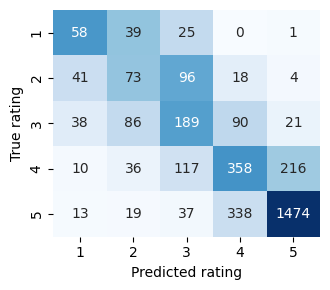

Most confused pairs (true,pred,count): [(5, 4, 338), (4, 5, 216), (4, 3, 117), (2, 3, 96), (3, 4, 90)]


In [7]:
pred = best_pipe.predict(X_te)
cm = confusion_matrix(y_te, pred, labels=[1, 2, 3, 4, 5]); cmn = cm / cm.sum(1, keepdims=True)
print(cm)
plt.figure(figsize=(3.4, 3)); sns.heatmap(cmn, annot=cm, fmt='d', cmap='Blues', xticklabels=range(1, 6), yticklabels=range(1, 6), cbar=False)
plt.xlabel('Predicted rating'); plt.ylabel('True rating'); plt.tight_layout(); plt.savefig('figures/b3_confusion.png', dpi=300); plt.show()
print('Most confused pairs (true,pred,count):', sorted([(i + 1, j + 1, int(cm[i, j])) for i in range(5) for j in range(5) if i != j], key=lambda t: -t[2])[:5])

## 6.2 Ablation (mandatory): structured-only vs text-only vs combined, using the best model

In [8]:
abl = []
for name, (ut, us) in {'structured only': (False, True), 'text only': (True, False), 'combined': (True, True)}.items():
    p = Pipeline([('pre', make_pre(ut, us)), ('clf', make_clf(best_key[0], best_key[2], None if best_key[1] == 'None' else best_key[1]))]).fit(X_tr, y_tr)
    abl.append(dict(features=name, **metrics(y_te, p.predict(X_te))))
abl_df = pd.DataFrame(abl); abl_df.to_csv('results/b3_ablation.csv', index=False); display(abl_df)
print(abl_df[['features', 'accuracy', 'macro_f1', 'weighted_f1', 'ordinal_mae']].to_latex(index=False, float_format='%.3f'))

,features,accuracy,macro_f1,weighted_f1,ordinal_mae,recall_1,recall_2,recall_3,recall_4,recall_5
0,structured only,0.279,0.201,0.319,1.476,0.195,0.151,0.172,0.278,0.324
1,text only,0.635,0.486,0.644,0.446,0.447,0.336,0.448,0.486,0.784
2,combined,0.634,0.484,0.643,0.450,0.472,0.315,0.446,0.486,0.784


\begin{tabular}{lrrrr}
\toprule
features & accuracy & macro_f1 & weighted_f1 & ordinal_mae \\
\midrule
structured only & 0.279 & 0.201 & 0.319 & 1.476 \\
text only & 0.635 & 0.486 & 0.644 & 0.446 \\
combined & 0.634 & 0.484 & 0.643 & 0.450 \\
\bottomrule
\end{tabular}



## 7. Re-framing: 3-class version (1-2 negative, 3 neutral, 4-5 positive)

In [9]:
to3 = lambda a: np.where(a <= 2, 0, np.where(a == 3, 1, 2))
p3 = Pipeline([('pre', make_pre()), ('clf', make_clf(best_key[0], best_key[2], None if best_key[1] == 'None' else best_key[1]))]).fit(X_tr, to3(y_tr))
m3 = metrics(to3(y_te), p3.predict(X_te)); print('3-class:', {k: round(v, 3) for k, v in m3.items()})
# fair comparison: collapse the 5-class predictions to 3 classes
m5to3 = metrics(to3(y_te), to3(pred)); print('5-class predictions collapsed to 3:', {k: round(v, 3) for k, v in m5to3.items()})
json.dump(dict(three_class=m3, five_collapsed=m5to3), open('results/b3_three_class.json', 'w'), indent=2)

3-class: {'accuracy': 0.82, 'macro_f1': 0.656, 'weighted_f1': 0.833, 'ordinal_mae': 0.204, 'recall_0': np.float64(0.597), 'recall_1': np.float64(0.564), 'recall_2': np.float64(0.892)}
5-class predictions collapsed to 3: {'accuracy': 0.82, 'macro_f1': 0.635, 'weighted_f1': 0.826, 'ordinal_mae': 0.21, 'recall_0': np.float64(0.594), 'recall_1': np.float64(0.446), 'recall_2': np.float64(0.911)}


## 6.2 Error analysis: top words and misclassified reviews

In [10]:
clf = best_pipe.named_steps['clf']; pre = best_pipe.named_steps['pre']
if hasattr(clf, 'coef_'):
    names = np.array(pre.get_feature_names_out())
    for cls_i, cls in enumerate(clf.classes_):
        if cls in (1, 5):
            top = np.argsort(clf.coef_[cls_i])[-12:][::-1]
            print(f'rating {cls} top features:', list(names[top]))
te = X_te.copy(); te['true'] = y_te; te['pred'] = pred
wrong = te[te.true != te.pred].copy(); wrong['gap'] = (wrong.true - wrong.pred).abs()
for _, r in wrong.sort_values('gap', ascending=False).head(3).iterrows():
    print(f'\nTRUE {r.true} / PRED {r.pred}: {r.text[:300]}')
wrong.sort_values('gap', ascending=False).head(30).to_csv('results/b3_misclassified.csv', index=False)

rating 1 top features: ['tfidf__terrible', 'tfidf__poor', 'tfidf__cheap', 'tfidf__disappointed', 'tfidf__even', 'tfidf__awful', 'tfidf__not as', 'tfidf__tent', 'tfidf__unflattering', 'tfidf__not', 'tfidf__too small', 'tfidf__unwearable']
rating 5 top features: ['tfidf__love', 'tfidf__perfect', 'tfidf__great', 'tfidf__love this', 'tfidf__comfortable', 'tfidf__perfectly', 'tfidf__flattering', 'tfidf__not too', 'tfidf__soft', 'tfidf__amazing', 'tfidf__beautiful', 'tfidf__gorgeous']

TRUE 5 / PRED 1: Unexpected color. First of all, the one that looks white is actually a powder blue color. this isn't necessarily bad, but i would have really liked a white one and i was disappointed when it arrived blue. i should have looked more closely at the picture and paid attention to the very unreliable colo

TRUE 5 / PRED 1: Forget-me-not!. This dress is extremely feminine. the liner is the unsung hero here: it's cleverly designed to be fitted because on a windy day and the dress flies up, it's a savi